# Lab 2 — Satellite data acquisition & evaluation

**Objective:** acquire monthly precipitation, ET, LAI and biomass for the West Rapti basin on the canonical WA+ grid, bias-correct the precipitation against DHM gauges, and check the basin water balance closes.

**Depends on Lab 1:** `gridspec.json`, `basin_mask.nc`, `dem_utm.tif` (pulled from Drive in section 2).

Runs on **Google Colab** (Earth Engine) and, for the analysis half, locally. GEE cells are marked ⚠️ — they need an authenticated Earth Engine project. The analysis helpers in `west_rapti.py` are unit-tested.

### 🧭 What we are really doing here

This is the shopping trip. The sheets later need rainfall, evaporation, leaf area and biomass — none of which we measure on the ground across a whole basin — so we go and fetch them from satellites on Earth Engine, already snapped to our grid.

Two ideas are worth holding onto. First, **rainfall is the biggest number in the entire account**, so we do not take the satellite estimate on faith — we pull it toward the DHM rain gauges (the bias-correction step), because a 10% error here becomes a 10% error in every sheet downstream. Second, **we never fully trust any single ET product** — we sanity-check it by asking whether the basin water balance can even close, $P - ET \approx Q + \Delta S$. If the ET is so large the basin would have to run dry, it is the ET that is wrong, not the rain.

By the end you will have four clean monthly stacks sitting on Drive that Lab 3 picks up.

## 0 · Environment setup  *(Colab or local — auto-detected)*

**What this does.** Detects whether you are on Google Colab, mounts your Google Drive, points
the notebook at the shared **`west_rapti`** folder (`KW_DIR` / `OUT_DIR`), installs the few extra
packages, and imports the engine module `west_rapti` as `kw`.

**Why.** Every later cell reads Lab 1's outputs from — and writes Lab 2's outputs to — that one
Drive folder, so the whole training shares a single source of truth.

**Check.** It should print the paths and finish without an import error. If `west_rapti` fails to
import, the folder isn't on the path — fix `KW_DIR` before continuing.

In [2]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    KW_DIR = '/content/drive/MyDrive/west_rapti'          # folder holding west_rapti.py
    get_ipython().system('pip -q install earthengine-api geemap geedim rioxarray wapordl')
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 95.7 MB/s eta 0:00:00
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 1 · Imports, Earth Engine auth & **configuration**

**What this does.** Loads the scientific stack, then sets the run **CONFIG** — the only knobs you
normally touch:

| knob | meaning |
|---|---|
| `START,END` | analysis window (monthly, END exclusive) |
| `EE_PROJECT` | your Earth Engine cloud project |
| `ET_SOURCE` | evapotranspiration product (`mod16` or `wapor`) |
| `NDM_SOURCE` | biomass product (`mod17` GPP or `wapor` NPP) |
| `ET_SPLIT` | how Sheet-2 beneficial ET is split (`lu` or physical `wapor` transpiration) |
| `PRECIP_BC` | rainfall bias-correction method (`monthly` recommended) |
| `DHM_STATIONS`,`DHM_OBS` | the gauge files (built from `HydroMetData/`) |

**Check.** It prints the number of months and the date range. Make sure the window sits inside the
coverage of every product you selected.

In [3]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rioxarray, xarray as xr, json
import importlib, west_rapti as kw; importlib.reload(kw)

# ---------------- CONFIG (edit these) ----------------
START, END = '2021-01-01', '2025-01-01'   # analysis period — within MOD17A2HGF GPP coverage (GEE 2021-2025)
EE_PROJECT = EE_PROJECT or 'your-ee-project-id'          # <-- your Earth Engine Cloud project (West Rapti @ Kusum case)
ET_SOURCE  = 'wapor'                       # 'mod16' (MOD16A2GF, GEE) | 'wapor' (WaPOR v3 AETI, native GEE)
NDM_SOURCE = 'mod17'                       # biomass: 'mod17' (GPP MOD17A2HGF, GEE) | 'wapor' (NPP via wapordl; v3 NPP not on GEE yet)
ET_SPLIT   = 'lu'                          # Sheet-2 beneficial ET: 'lu' (land-use fraction) | 'wapor' (physical: WaPOR v3 transpiration T)
                                           #   'wapor' downloads L1-T-D and saves transp.nc; use with ET_SOURCE='wapor' so T <= AETI. Green/blue stays source-based in Lab 4.
DHM_STATIONS = 'dhm_stations.csv'          # columns: id,lon,lat,elev   (see section 5)
DHM_OBS      = 'dhm_precip.csv'            # monthly gauge precip: index=date, cols=station ids
PRECIP_BC    = 'elevation_idw'                 # bias correction: 'elevation' (best here per leave-one-out) | 'elev_idw' | 'monthly' | 'annual'
USE_OUTSIDE_GAUGES = True                  # add outside-basin gauges near the edge as extra IDW anchors
OUTSIDE_BUFFER_KM  = 25                     # 'near the edge' = within this many km of the basin boundary
# -----------------------------------------------------
DATES = pd.date_range(START, END, freq='MS')[:-1]      # first-of-month, exclusive END
N = len(DATES); print(N, 'months', DATES[0].date(), '->', DATES[-1].date())

48 months 2021-01-01 -> 2024-12-01


**Earth Engine sign-in.** On Colab this opens a consent link once per session; paste the
token back. It then initialises EE against your `EE_PROJECT`. Nothing downloads yet — this only
authenticates.

In [4]:
# ⚠️ Earth Engine auth (Colab): opens a consent link, then initialises your project.
import ee
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
print('Earth Engine ready')

Earth Engine ready


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## 2 · Pull Lab 1 outputs from Drive

**What this does.** Brings in the three things Lab 1 produced — the **grid specification**
(`gridspec.json`), the **basin mask**, and the **DEM** — and builds the objects every later cell
needs: the common WA+ grid, the GEE bounding box (`region`), the DEM regridded onto the precip
grid, and the basin `mask`.

**Why.** Lab 2 must live on *exactly* the grid Lab 1 defined, or nothing lines up downstream.

**Check.** It prints the grid size, CRS and bbox — confirm they match your Lab 1 basin.

In [5]:
kw.load_inputs(['gridspec.json','basin_mask.nc','dem_utm.tif'], OUT_DIR)
gs = json.load(open('gridspec.json'))
BBOX = kw.lonlat_bbox(gs)                      # [W,S,E,N] for GEE
UTM  = gs['crs']; WA_RES = gs['res']
dem  = kw.regrid('dem_utm.tif', gs).squeeze(drop=True)   # DEM on the WA+ grid, matching the precip cube
mask = xr.open_dataset('basin_mask.nc')['basin_mask']
region = ee.Geometry.Rectangle(BBOX)
print('grid', gs['width'],'x',gs['height'],'@',WA_RES,'m |', UTM, '| bbox', [round(v,3) for v in BBOX])

grid 556 x 394 @ 300 m | EPSG:32644 | bbox [81.531, 27.585, 83.284, 28.709]


## 3 · Acquire monthly satellite stacks from Earth Engine  ⚠️

**What this does.** Downloads and **aggregates to monthly** every product the CONFIG asked for:
precipitation (CHIRPS), evapotranspiration (MOD16 or WaPOR AETI), biomass (MOD17 GPP or WaPOR NPP),
LAI, and — if `ET_SPLIT='wapor'` — transpiration. Helper functions handle the two aggregation
styles: `monthly_image` sums/means daily & 8-day products; `wapor_monthly_et` converts WaPOR's
dekadal *mm/day* to a monthly total. `download_fast` tiles the download so it stays under Earth
Engine's request limit.

**Why.** These monthly grids are the raw material for the WA+ water balance.

**Heads-up.** This is the slow, network-heavy cell. The `Connection pool is full` warnings are
harmless (parallel tiles). If a product errors, check its GEE asset id / coverage for your window.

In [6]:
import os
import time
import urllib.request
import ee
import geemap
import geedim as gd

# -------------------------------------------------------------------------
# 1. Initialize Earth Engine API
# -------------------------------------------------------------------------
try:
    ee.Initialize(project=EE_PROJECT)
    print(f'Successfully initialized Earth Engine with project: {EE_PROJECT}')
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)


# -------------------------------------------------------------------------
# 2. Optimized GEE Monthly Aggregator  (daily / 8-day composites -> monthly)
# -------------------------------------------------------------------------
def monthly_image(cid, band, how='sum', scale=1.0, vmax=None):
    ic = (ee.ImageCollection(cid).select(band)
          .filterDate(START, END).filterBounds(region))
    if vmax is not None:
        ic = ic.map(lambda im: im.updateMask(im.lte(vmax)))

    def one(i):
        s = ee.Date(START).advance(i, 'month')
        m = ic.filterDate(s, s.advance(1, 'month'))
        red = m.sum() if how == 'sum' else m.mean()
        img = ee.Image(ee.Algorithms.If(m.size().gt(0), red,
                                        ee.Image.constant(0).selfMask()))
        img = img.multiply(scale).toFloat()
        return img.rename('b').set('t', s.format('YYYY-MM'))

    imgs = ee.List.sequence(0, N - 1).map(one)
    return ee.ImageCollection(imgs).toBands()


# -------------------------------------------------------------------------
# 3. WaPOR dekadal (mm/day) -> monthly total (mm)
#    FAO method: depth = rate(mm/day) * days_in_dekad ; monthly = sum of 3 dekads.
#    Scale factors: AETI / E / T / I = 0.1 ;  NPP = 0.001  (pass via `scale`).
# -------------------------------------------------------------------------
def wapor_monthly_et(cid, band, scale=0.1):
    """WaPOR v3 dekadal layers are daily RATES (mm/day, stored × 1/scale). Monthly depth (mm) =
    sum over the month's dekads of rate × scale × days in that dekad (10, 10, month length − 20)."""
    ic = (ee.ImageCollection(cid).select(band)
          .filterDate(START, END).filterBounds(region))

    def dekad_depth(img):
        t0 = img.date(); d = ee.Number(t0.get('day'))
        first = ee.Date.fromYMD(t0.get('year'), t0.get('month'), 1)
        days_in_month = first.advance(1, 'month').difference(first, 'day')
        n_days = ee.Number(ee.Algorithms.If(d.lte(20), 10, days_in_month.subtract(20)))   # dekads start 1, 11, 21
        depth = img.multiply(scale).multiply(n_days).toFloat()
        return ee.Image(depth.copyProperties(img, ['system:time_start'])).set('n_days', n_days)   # keep it an Image

    ic_depth = ic.map(dekad_depth)

    def one_month(i):
        s = ee.Date(START).advance(i, 'month')
        m = ic_depth.filterDate(s, s.advance(1, 'month'))
        monthly_sum = ee.Image(ee.Algorithms.If(m.size().gt(0), m.sum(), ee.Image.constant(0))).toFloat()
        return monthly_sum.rename('b').set('t', s.format('YYYY-MM')).set('n_dekads', m.size())

    imgs = ee.List.sequence(0, N - 1).map(one_month)
    return ee.ImageCollection(imgs).toBands()


def wapor_check(cid='FAO/WAPOR/3/L1_AETI_D', band='L1-AETI-D', scale=0.1):
    """Print the evidence: dekads per month (must be 3), the first month's dekads, and the
    annual basin ET from WaPOR vs MOD16 (computed on Google's servers at 5 km)."""
    ic = ee.ImageCollection(cid).select(band).filterDate(START, END).filterBounds(region)
    n = ee.List.sequence(0, 11).map(lambda i: ic.filterDate(ee.Date(START).advance(i, 'month'),
                                                            ee.Date(START).advance(ee.Number(i).add(1), 'month')).size()).getInfo()
    print('WaPOR dekads found per month (first 12 months; each must be 3):', n)
    first = ic.filterDate(START, ee.Date(START).advance(1, 'month'))
    rows = first.map(lambda im: ee.Feature(None, {'date': im.date().format('YYYY-MM-dd'),
              'rate': im.reduceRegion(ee.Reducer.mean(), region, 5000, maxPixels=1e9).get(band)})).getInfo()['features']
    for f in rows:
        p = f['properties']; d = int(p['date'][-2:]); r = (p['rate'] or 0) * scale
        nd = 10 if d <= 20 else (pd.Timestamp(p['date']).days_in_month - 20)
        print(f"   dekad {p['date']}: {r:.2f} mm/day × {nd} days = {r * nd:.1f} mm")
    w = wapor_monthly_et(cid, band, scale)
    wap = w.reduce(ee.Reducer.sum()).divide(max(N / 12, 1)).reduceRegion(ee.Reducer.mean(), region, 5000, maxPixels=1e9).getInfo()
    mod = (ee.ImageCollection('MODIS/061/MOD16A2GF').select('ET').filterDate(START, END).filterBounds(region)
           .map(lambda im: im.updateMask(im.lte(32700))).sum().multiply(0.1).divide(max(N / 12, 1))
           .reduceRegion(ee.Reducer.mean(), region, 5000, maxPixels=1e9).getInfo())
    wv = list(wap.values())[0] if wap else None; mv = mod.get('ET')
    print(f'mean annual basin-box ET: WaPOR {wv:.0f} mm/yr   vs   MOD16 {mv:.0f} mm/yr' if wv and mv else (wap, mod))
    if wv and mv and wv < 0.5 * mv:
        print('⚠️  WaPOR is less than half of MOD16 — check the dekad counts above (fewer than 3 per month = dekads dropped).')

# -------------------------------------------------------------------------
# 4. Robust High-Speed Downloader  (geedim tiles; URL / geemap fallbacks)
# -------------------------------------------------------------------------
def download_fast(ee_img, filename, scale, region, crs):
    t0 = time.time()
    try:
        gd_img = gd.MaskedImage(ee_img)
        gd_img.download(filename, region=region, scale=scale, crs=crs,
                        overwrite=True, max_tile_size=32)
        print(f'✓ Completed {filename} via geedim in {time.time() - t0:.2f}s')
    except Exception as e:
        print(f'geedim failed for {filename} ({e}), trying direct URL...')
        try:
            url = ee_img.getDownloadURL({
                'name': filename.replace('.tif', ''),
                'scale': scale, 'crs': crs, 'region': region, 'format': 'GEO_TIFF'})
            urllib.request.urlretrieve(url, filename)
            print(f'✓ Completed {filename} via Direct URL in {time.time() - t0:.2f}s')
        except Exception as err:
            print(f'URL failed ({err}), falling back to geemap tiled download...')
            geemap.download_ee_image(ee_img, filename, scale=scale, region=region, crs=crs)


# -------------------------------------------------------------------------
# 5. Main Execution
# -------------------------------------------------------------------------
start_all = time.time()

# Standard jobs (daily CHIRPS precip / 8-day MODIS LAI)
jobs = {
    'P_chirps': ('UCSB-CHG/CHIRPS/DAILY', 'precipitation', 'sum', 1.0, None),
    'LAI_mod15': ('MODIS/061/MOD15A2H', 'Lai_500m', 'mean', 0.1, 100),
}

print('=== Processing Main GEE Jobs ===')
for name, (cid, band, how, sc, vm) in jobs.items():
    img = monthly_image(cid, band, how, sc, vm)
    download_fast(img, f'{name}.tif', scale=WA_RES, region=region, crs=UTM)

# --- Evapotranspiration (ET) ---
print('\n=== Processing Evapotranspiration (ET) ===')
if ET_SOURCE == 'wapor':
    img = wapor_monthly_et('FAO/WAPOR/3/L1_AETI_D', 'L1-AETI-D', scale=0.1)
    ET_TIF = 'ET_wapor.tif'
    download_fast(img, ET_TIF, scale=WA_RES, region=region, crs=UTM)
    try:
        wapor_check()                 # dekads per month + WaPOR vs MOD16 annual ET
    except Exception as e:
        print('WaPOR check skipped:', e)
else:
    img = monthly_image('MODIS/061/MOD16A2GF', 'ET', 'sum', 0.1, 32700)
    ET_TIF = 'ET_mod16.tif'
    download_fast(img, ET_TIF, scale=WA_RES, region=region, crs=UTM)

# --- NDM / Biomass ---
print('\n=== Processing Biomass / NDM ===')
if NDM_SOURCE == 'wapor':
    img = wapor_monthly_et('FAO/WAPOR/3/L1_NPP_D', 'L1-NPP-D', scale=0.001)  # NPP scale = 0.001, not 0.1
    NDM_TIF = 'NDM_wapor.tif'
    download_fast(img, NDM_TIF, scale=WA_RES, region=region, crs=UTM)
else:
    img = monthly_image('MODIS/061/MOD17A2HGF', 'Gpp', 'sum', 0.0001, 30000)
    NDM_TIF = 'GPP_mod17.tif'
    download_fast(img, NDM_TIF, scale=WA_RES, region=region, crs=UTM)

# --- Transpiration (T), optional Sheet-2 physical split ---
if ET_SPLIT == 'wapor':
    print('\n=== Processing WaPOR Transpiration ===')
    img = wapor_monthly_et('FAO/WAPOR/3/L1_T_D', 'L1-T-D', scale=0.1)
    download_fast(img, 'T_wapor.tif', scale=WA_RES, region=region, crs=UTM)

print(f'\n🎉 All datasets downloaded in {time.time() - start_all:.2f} seconds!')

Successfully initialized Earth Engine with project: gee-training-nepal-wecs-2026
=== Processing Main GEE Jobs ===


/usr/local/lib/python3.13/dist-packages/geedim/mask.py:579: FutureWarning: 'MaskedImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  super().__init__(ee_image)


  0%|          |0/4 tiles [00:00<?]

/usr/local/lib/python3.13/dist-packages/geedim/image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


✓ Completed P_chirps.tif via geedim in 7.36s


...

✓ Completed LAI_mod15.tif via geedim in 13.60s

=== Processing Evapotranspiration (ET) ===


  0%|          |0/4 tiles [00:00<?]

✓ Completed ET_wapor.tif via geedim in 21.22s
WaPOR dekads found per month (first 12 months; each must be 3): [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
   dekad 2021-01-01: 1.26 mm/day × 10 days = 12.6 mm
   dekad 2021-01-11: 0.73 mm/day × 10 days = 7.3 mm
   dekad 2021-01-21: 0.74 mm/day × 11 days = 8.1 mm
mean annual basin-box ET: WaPOR 756 mm/yr   vs   MOD16 661 mm/yr

=== Processing Biomass / NDM ===


  0%|          |0/4 tiles [00:00<?]

✓ Completed GPP_mod17.tif via geedim in 8.43s

🎉 All datasets downloaded in 52.04 seconds!


## 4 · Put everything on the common WA+ grid  *(NetCDF, basin-masked)*

**What this does.** Regrids each downloaded GeoTIFF onto the shared WA+ grid, masks it to the basin,
and saves it as a NetCDF cube (`P.nc`, `ET.nc`, `LAI.nc`, `NDM.nc`, …). From here on everything is
an aligned `xarray` cube on one grid.

**Check.** The printed shapes should all be `(months, height, width)` and identical across products.

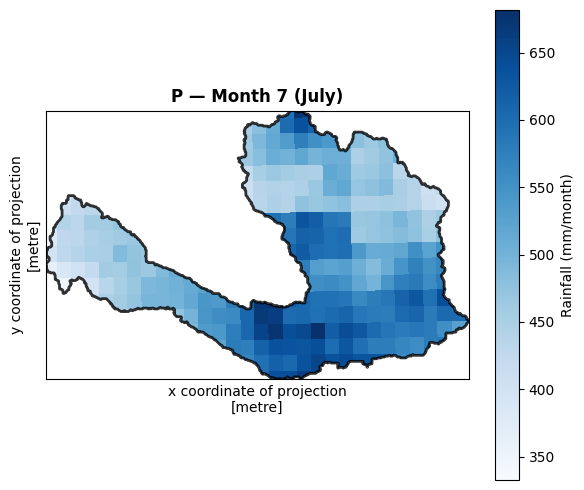

cubes: {'P': (48, 394, 556), 'ET': (48, 394, 556), 'LAI': (48, 394, 556), 'NDM': (48, 394, 556)}


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import os # Ensure os is imported for os.path.exists

# -------------------------------------------------------------------------
# 1. Load Data Cubes from Downloaded GeoTIFFs
# -------------------------------------------------------------------------
# Precipitation (CHIRPS)
P = kw.tif_stack_to_nc('P_chirps.tif', 'P', DATES, gs, nc='P.nc')

# Evapotranspiration (WaPOR or MODIS)
nb_et = rioxarray.open_rasterio(ET_TIF).sizes['band']
ET = kw.tif_stack_to_nc(ET_TIF, 'ET', DATES[:nb_et], gs, nc='ET.nc')
ET = ET.where(ET >= 0)  # Mask out nodata values

# Leaf Area Index (MODIS)
LAI = kw.tif_stack_to_nc('LAI_mod15.tif', 'LAI', DATES, gs, nc='LAI.nc')
LAI = LAI.where(LAI >= 0)

# Biomass Proxy / NDM (WaPOR or MODIS)
nb_ndm = rioxarray.open_rasterio(NDM_TIF).sizes['band']
NDM = kw.tif_stack_to_nc(NDM_TIF, 'NDM', DATES[:nb_ndm], gs, nc='NDM.nc')
NDM = NDM.where(NDM >= 0)

# -------------------------------------------------------------------------
# 2. Derive Mask from Valid Raster Pixels (The 'mask' variable is already
#    defined from basin_mask.nc in a previous cell, so no re-definition here)
# -------------------------------------------------------------------------

# -------------------------------------------------------------------------
# 3. Calculate Basin Extent Bounding Box
# -------------------------------------------------------------------------
x_name = mask.dims[-1]  # usually 'x' or 'lon'
y_name = mask.dims[-2]  # usually 'y' or 'lat'

# Find valid spatial coordinates where mask is 1 (using the correct basin mask)
valid_coords = mask.where(mask == 1, drop=True)

x_min, x_max = valid_coords[x_name].min().item(), valid_coords[x_name].max().item()
y_min, y_max = valid_coords[y_name].min().item(), valid_coords[y_name].max().item()

# -------------------------------------------------------------------------
# 4. Crop and Plot Month 7 (July)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

# Mask data using the correct basin mask
plot_data_masked = P.isel(time=6).where(mask == 1)

im = plot_data_masked.plot(ax=ax, cmap='Blues', add_colorbar=False) # Plot the masked data
fig.colorbar(im, ax=ax, label='Rainfall (mm/month)')

# Create a binary mask for contouring (1 inside, 0 outside) and ensure float type
binary_mask_for_contour = (mask == 1).astype(float)
# Add a contour of the basin mask to explicitly show the boundary with increased visibility
binary_mask_for_contour.plot.contour(ax=ax, colors='black', levels=[0.5], add_colorbar=False, linewidths=2, alpha=0.8)

# Apply tight spatial zoom using the calculated bounding box with a small buffer
ax.set_xlim(x_min - WA_RES / 2, x_max + WA_RES / 2)
if y_min < y_max:
    ax.set_ylim(y_min - WA_RES / 2, y_max + WA_RES / 2)
else:
    # If y-coordinates are inverted, expand outwards from y_max (smaller value) to y_min (larger value)
    ax.set_ylim(y_max + WA_RES / 2, y_min - WA_RES / 2)

ax.set_title('P — Month 7 (July)', fontweight='bold', fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

# Added back the transpiration loading logic that was in the latest failed state
if os.path.exists('T_wapor.tif'):
    nb_t = rioxarray.open_rasterio('T_wapor.tif').sizes['band']
    kw.tif_stack_to_nc('T_wapor.tif', 'transp', DATES[:nb_t], gs, nc='transp.nc')
    print('transpiration -> transp.nc (feeds Lab 5 Sheet 2 beneficial ET)')

print(
    'cubes:', {k: v.shape for k, v in dict(P=P, ET=ET, LAI=LAI, NDM=NDM).items()}
)


## 5 · Quality check — 12-month climatology maps

**What this does.** For each variable it draws the mean of every calendar month (Jan…Dec) as a map,
so you can *see* the seasonality and spot anything unphysical before it propagates into the sheets.

**What to look for.** Monsoon precipitation peaking Jun–Sep; ET tracking vegetation; no blank months,
no obviously wrong magnitudes, no stripes or tiles. This is the eyeball QC step.

In [8]:
# 12 panels per variable: mean of each calendar month across the period (basin only)
def month_grid(da, title, cmap, units):
    # 1. Apply mask AND drop outer NaN borders automatically
    masked_da = da.where(mask == 1)
    clim = masked_da.groupby('time.month').mean('time').where(mask == 1, drop=True) # (month, y, x)

    finite = clim.values[np.isfinite(clim.values)]
    if finite.size == 0:
        print('!! ', title, '— no valid pixels (check masking/coverage)'); return

    # Detect coordinate names (handles 'x'/'y', 'lon'/'lat', etc.)
    x_name = clim.dims[-1]
    y_name = clim.dims[-2]

    vmin, vmax = np.nanpercentile(finite, 2), np.nanpercentile(finite, 98)
    fig, axs = plt.subplots(3, 4, figsize=(13, 8.2), constrained_layout=True)
    im = None

    for m, ax in zip(range(1, 13), axs.ravel()):
        if m in clim['month'].values:
            im = clim.sel(month=m).plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap=cmap,
                                               add_colorbar=False, add_labels=False)

        ax.set_title(pd.Timestamp(2001, m, 1).strftime('%b'), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')

    if im is not None: fig.colorbar(im, ax=axs, shrink=0.55, label=units)
    fig.suptitle(title, fontsize=13, fontweight='bold'); plt.show()

    bmean = clim.mean(dim=[y_name, x_name]).values
    print(title, '\n   basin monthly mean (Jan..Dec):',
          np.array2string(np.round(bmean, 1), separator=', '))

month_grid(P,   'Rainfall — monthly climatology',       'Blues',  'mm/month')
month_grid(ET,  'ET — monthly climatology',            'YlOrBr', 'mm/month')
month_grid(LAI, 'Leaf area index — monthly climatology','Greens', 'LAI (m2/m2)')
# Updated call with explicit scientific units
month_grid(
    NDM,
    'Biomass proxy (NDM) — monthly climatology',
    'viridis',
    ('kg C/m²/month' if NDM_SOURCE == 'mod17' else 'WaPOR NPP units/month')  # MOD17 Gpp × 0.0001 = kg C/m² per 8 days, summed per month
)

Output hidden; open in https://colab.research.google.com to view.

**Per-product summary statistics** — basin-mean annual totals for each variable, a quick
numeric sanity check to accompany the maps above (e.g. annual precipitation in a plausible range for
the West Rapti).

In [9]:
import pandas as pd

# Recalculate ET monthly climatology
# This step re-uses the mask and the ET DataArray from previous cells
masked_et = ET.where(mask == 1)
et_clim = masked_et.groupby('time.month').mean('time').where(mask == 1, drop=True)

# Get the spatial dimension names
x_name = et_clim.dims[-1]
y_name = et_clim.dims[-2]

# Calculate the basin mean for each month
bmean_et = et_clim.mean(dim=[y_name, x_name]).values

# Create a DataFrame for better display
months = pd.date_range(start='2020-01-01', periods=12, freq='MS').strftime('%b').tolist()
df_monthly_et = pd.DataFrame({
    'Month': months,
    'Average ET (mm/month)': np.round(bmean_et, 2)
})
display(df_monthly_et)


,Month,Average ET (mm/month)
0,Jan,24.360001
1,Feb,41.430000
2,Mar,72.900002
3,Apr,93.660004
4,May,81.629997
5,Jun,86.970001
6,Jul,77.680000
7,Aug,78.730003
8,Sep,75.870003
9,Oct,69.849998


### ✅ Checkpoint — do the products look physical?
Each variable shows a **seasonal cycle** (monsoon-driven), the basin shape is filled (no big blank blocks), and the printed monthly means rise and fall sensibly (rainfall & ET peak Jun–Sep). If ET or biomass is flat or empty, switch the source (`ET_SOURCE`, `NDM_SOURCE`) and re-run §3–4 before continuing — this is the cheapest place to catch a bad input.

## 6 · Look at the rainfall first — basin, gauges (in & outside) & CHIRPS

Before correcting anything, **see the data**: where the DHM rain gauges sit relative to the basin —
including gauges **outside** the divide that DHM also provided — the gauge rainfall (daily & monthly),
and how CHIRPS compares at those points. Gauges just outside the boundary carry real information for
basin-edge pixels, so (with `USE_OUTSIDE_GAUGES`) the ones within `OUTSIDE_BUFFER_KM` are added as
extra **IDW anchors** for the correction in §7.

**Load the gauges & choose the edge anchors.** Reads in-basin and outside gauges straight from `HydroMetData/`, measures each outside gauge's distance to the basin boundary, and merges the near ones into the anchor set (`stations`, `obs`).

In [10]:
import os, numpy as np, pandas as pd, geopandas as gpd, westrapti_prep as wp
from rasterio import features
from rasterio.transform import Affine
from shapely.geometry import shape
from shapely.ops import unary_union

_base = KW_DIR if 'KW_DIR' in dir() else '.'
def _find_hydromet(base):
    for root, _d, files in os.walk(base):
        if 'rapti_rain.xlsx' in files and os.path.basename(root) == 'Temp_PPT':
            return os.path.dirname(root)
    return None
_hm = _find_hydromet(_base)

# basin boundary polygon (lon/lat), vectorised from the mask
_tr  = Affine(gs['res'], 0, gs['te'][0], 0, -gs['res'], gs['te'][3])
_mk  = np.asarray(np.asarray(mask) == 1, 'uint8')
basin = gpd.GeoDataFrame(
    geometry=[unary_union([shape(g) for g, v in features.shapes(_mk, mask=_mk.astype(bool), transform=_tr) if v == 1])],
    crs=gs['crs']).to_crs(4326)

# in-basin gauges (from HydroMetData, else the shipped CSVs)
if _hm:
    stations_in, obs_in = wp.dhm_frames(_hm, START, END)
    daily_in = wp.dhm_daily(_hm)
else:
    stations_in = pd.read_csv(os.path.join(_base, 'dhm_stations.csv'))
    obs_in = pd.read_csv(os.path.join(_base, 'dhm_precip.csv'), index_col=0, parse_dates=True); daily_in = None

# OUTSIDE-basin gauges (same file layout) — read straight from HydroMetData
stations_out = obs_out = daily_out = None
if _hm and os.path.exists(os.path.join(_hm, 'Temp_PPT', 'OutsideBasin_Rainfall.xlsx')):
    stations_out, obs_out = wp.dhm_frames(_hm, START, END, fname='OutsideBasin_Rainfall.xlsx')
    daily_out = wp.dhm_daily(_hm, fname='OutsideBasin_Rainfall.xlsx')
    # distance of each outside gauge to the basin boundary (km), in the projected grid CRS
    _pts = gpd.GeoDataFrame(stations_out, geometry=gpd.points_from_xy(stations_out.lon, stations_out.lat),
                            crs=4326).to_crs(gs['crs'])
    stations_out = stations_out.assign(dist_km=_pts.geometry.distance(basin.to_crs(gs['crs']).geometry.iloc[0]) / 1000.0)

# merge: in-basin + outside gauges within OUTSIDE_BUFFER_KM  -> the anchor set the bias correction uses
_use = USE_OUTSIDE_GAUGES if 'USE_OUTSIDE_GAUGES' in dir() else True
_buf = OUTSIDE_BUFFER_KM if 'OUTSIDE_BUFFER_KM' in dir() else 25.0
near_out = stations_out[stations_out['dist_km'] <= _buf] if stations_out is not None else None
if _use and near_out is not None and len(near_out):
    keep = [c for c in near_out['id'] if c in obs_out.columns]
    stations = pd.concat([stations_in, near_out[near_out['id'].isin(keep)][['id','lon','lat','elev']]], ignore_index=True)
    obs = obs_in.join(obs_out[keep], how='outer')
    print(f"anchors: {len(stations_in)} in-basin + {len(keep)} near-outside (<= {_buf:.0f} km) = {len(stations)} gauges")
else:
    stations, obs = stations_in.copy(), obs_in.copy()
    print(f"anchors: {len(stations_in)} in-basin gauges" + (" (outside gauges shown only)" if stations_out is not None else ""))
gauge_daily = daily_in


anchors: 11 in-basin + 4 near-outside (<= 25 km) = 15 gauges


**Interactive map.** Basin outline with the gauges: **blue** = in-basin, **green** = outside gauge used as an anchor, **grey** = outside gauge too far to use.

In [11]:
import geemap
from ipyleaflet import CircleMarker
m = geemap.Map(basemap='Esri.WorldImagery', center=[float(stations_in['lat'].mean()), float(stations_in['lon'].mean())], zoom=8)
m.add_gdf(basin, layer_name='West Rapti basin',
          style={'color':'#1f3b57','fillColor':'#1f3b57','fillOpacity':0.06,'weight':2})
for _, r in stations_in.iterrows():                                  # in-basin = blue
    m.add(CircleMarker(location=(float(r['lat']), float(r['lon'])), radius=5,
          color='#1f78ff', fill_color='#1f78ff', fill_opacity=0.9, weight=1))
if stations_out is not None:
    for _, r in stations_out.iterrows():                             # green = used anchor, grey = outside/unused
        used = (USE_OUTSIDE_GAUGES if 'USE_OUTSIDE_GAUGES' in dir() else True) and r['dist_km'] <= (OUTSIDE_BUFFER_KM if 'OUTSIDE_BUFFER_KM' in dir() else 25.0)
        col = '#2ca02c' if used else '#8a939b'
        m.add(CircleMarker(location=(float(r['lat']), float(r['lon'])), radius=6,
              color=col, fill_color=col, fill_opacity=0.9, weight=1))
print('blue = in-basin gauge | green = outside gauge used as anchor | grey = outside gauge (too far)')
m


blue = in-basin gauge | green = outside gauge used as anchor | grey = outside gauge (too far)


Map(center=[28.10708315636364, 82.59750184454545], controls=(WidgetControl(options=['position', 'transparent_b…

**Gauge rainfall — daily & monthly**, in-basin vs outside means. This is the ground truth the correction pulls the satellite toward.

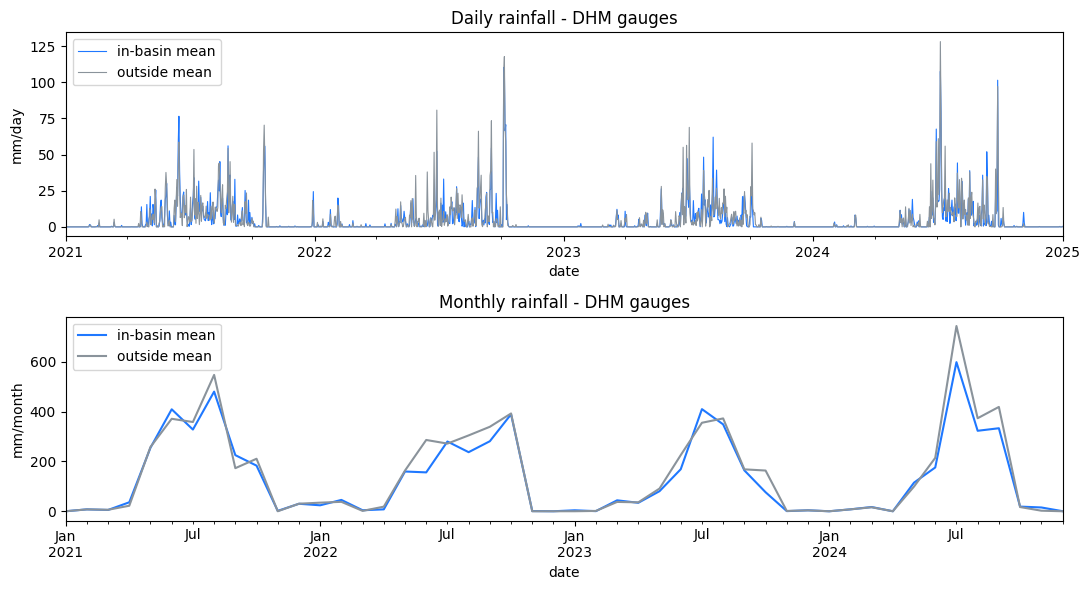

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
if daily_in is not None:
    daily_in.loc[START:END].mean(axis=1).plot(ax=ax[0], color='#1f78ff', lw=0.8, label='in-basin mean')
if daily_out is not None:
    daily_out.loc[START:END].mean(axis=1).plot(ax=ax[0], color='#8a939b', lw=0.8, label='outside mean')
ax[0].set_title('Daily rainfall - DHM gauges'); ax[0].set_ylabel('mm/day'); ax[0].legend()
obs_in.mean(axis=1).plot(ax=ax[1], color='#1f78ff', label='in-basin mean')
if obs_out is not None:
    obs_out.mean(axis=1).plot(ax=ax[1], color='#8a939b', label='outside mean')
ax[1].set_title('Monthly rainfall - DHM gauges'); ax[1].set_ylabel('mm/month'); ax[1].legend()
plt.tight_layout(); plt.show()


**CHIRPS at the anchor locations.** Sample the satellite at every anchor pixel (monthly + daily) and overlay it on the gauges — the gap you see is the bias §7 removes.

CHIRPS extracted at 15 anchor stations, 1461 days


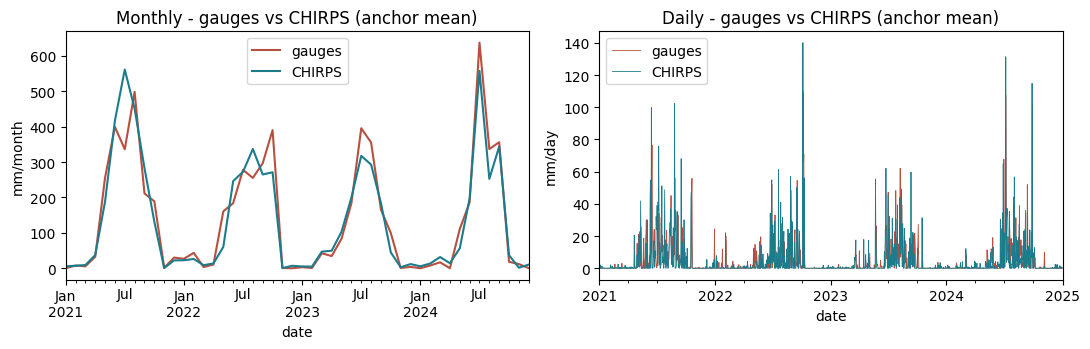

In [13]:
import ee
chirps_monthly = kw._station_pixel_values(P, stations, UTM)          # CHIRPS at every anchor pixel (monthly)
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
_ch = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation').filterDate(START, END)
chirps_daily = {}
for r in stations.itertuples():                                      # daily CHIRPS at the same points
    _a = _ch.getRegion(ee.Geometry.Point([float(r.lon), float(r.lat)]), 5000).getInfo()
    _d = pd.DataFrame(_a[1:], columns=_a[0]); _d['date'] = pd.to_datetime(_d['time'], unit='ms')
    chirps_daily[int(r.id)] = _d.set_index('date')['precipitation'].astype(float)
chirps_daily = pd.DataFrame(chirps_daily)
print('CHIRPS extracted at', chirps_daily.shape[1], 'anchor stations,', chirps_daily.shape[0], 'days')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
obs.mean(axis=1).plot(ax=ax[0], color='#B85042', label='gauges')
chirps_monthly.mean(axis=1).reindex(obs.index).plot(ax=ax[0], color='#1C7C8C', label='CHIRPS')
ax[0].set_title('Monthly - gauges vs CHIRPS (anchor mean)'); ax[0].set_ylabel('mm/month'); ax[0].legend()
if gauge_daily is not None:
    gauge_daily.loc[START:END].mean(axis=1).plot(ax=ax[1], color='#B85042', lw=0.6, label='gauges')
chirps_daily.mean(axis=1).plot(ax=ax[1], color='#1C7C8C', lw=0.6, label='CHIRPS')
ax[1].set_title('Daily - gauges vs CHIRPS (anchor mean)'); ax[1].set_ylabel('mm/day'); ax[1].legend()
plt.tight_layout(); plt.show()


## 7 · Bias-correct precipitation against DHM rain gauges

**What this does.** The satellite gets the *spatial pattern* of rainfall right but is biased in
*amount*. This cell corrects CHIRPS to the DHM gauges using `PRECIP_BC`:

- **`monthly`** *(default, recommended)* — a correction factor **per gauge, per calendar month**
  (Σgauge ÷ Σsatellite over the record), interpolated across the basin by **inverse-distance (IDW)**
  and applied month-by-month. Robust to sparse gauges and dry-month noise; captures the *spatial*
  bias, not just elevation.
- `annual` — one factor per gauge. `elevation` — legacy elevation regression.

**How it's validated.** It prints **leave-one-gauge-out RMSE** (lower = better transfer to ungauged
cells) for the chosen vs the legacy method, and draws a **gauge-vs-corrected scatter** (R² + RMSE).

**Check.** Corrected basin rainfall should sit closer to the gauges; the scatter should hug the 1:1
line. The corrected cube is saved as `P_corrected.nc`.

using the anchors prepared in section 6: 15 gauges, 48 months
gauges matched between the station list and the rainfall table: 15 of 15
bias method = elevation_idw | basin-mean change +14.6 mm/month
           LOO RMSE (mm/month)  LOO bias (mm/month)    n
method                                                  
elevation                 95.7                  9.2  647
elev_idw                 115.1                 -2.5  465
monthly                  110.6                 -3.3  465
annual                   123.3                 22.0  465
lowest leave-one-out error: elevation  (you chose elevation_idw — consider PRECIP_BC = 'elevation')


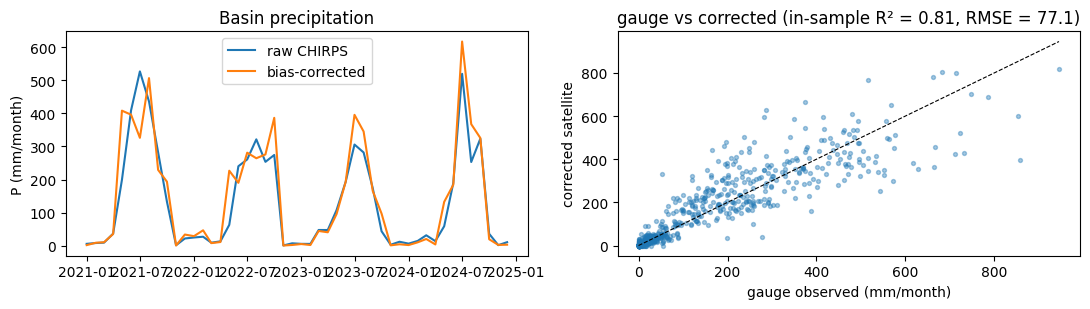

In [14]:
import os, numpy as np, pandas as pd

# --- locate the gauge CSVs: they ship in the west_rapti Drive folder (KW_DIR), not /content ---
_base = KW_DIR if 'KW_DIR' in dir() else '.'
for _v in ('DHM_STATIONS', 'DHM_OBS'):
    _p = globals()[_v]
    if not os.path.isabs(_p) and not os.path.exists(_p):
        _cand = os.path.join(_base, os.path.basename(_p))
        if os.path.exists(_cand):
            globals()[_v] = _cand

# --- if still absent, build them from a HydroMetData pack found anywhere under KW_DIR ---
def _find_hydromet(base):
    for root, _d, files in os.walk(base):
        if 'rapti_rain.xlsx' in files and os.path.basename(root) == 'Temp_PPT':
            return os.path.dirname(root)
    return None
if not (os.path.exists(DHM_STATIONS) and os.path.exists(DHM_OBS)):
    _hm = _find_hydromet(_base)
    if _hm:
        try:
            import westrapti_prep as wp
            _st, _pr = wp.dhm_frames(_hm, START, END)
            DHM_STATIONS = os.path.join(_base, 'dhm_stations.csv')
            DHM_OBS      = os.path.join(_base, 'dhm_precip.csv')
            _st.to_csv(DHM_STATIONS, index=False); _pr.to_csv(DHM_OBS)
            print('built gauge CSVs from', _hm, '->', len(_st), 'rain gauges')
        except Exception as e:
            print('gauge prep failed:', e)
    else:
        print('no dhm_*.csv and no HydroMetData/ found under', _base)

# --- load the REAL DHM rain gauges ---
if 'stations' in dir() and 'obs' in dir():
    print('using the anchors prepared in section 6:', len(stations), 'gauges,', obs.shape[0], 'months')
elif os.path.exists(DHM_STATIONS) and os.path.exists(DHM_OBS):
    stations = pd.read_csv(DHM_STATIONS)
    obs = pd.read_csv(DHM_OBS, index_col=0, parse_dates=True)
    print('using REAL DHM rainfall:', len(stations), 'gauges,', obs.shape[0], 'months')
else:
    raise SystemExit('No DHM gauge data found — run 00_Setup (cell 7) or ask the trainer for HydroMetData.')

# gauge ids as text in both tables (dhm_precip.csv stores them as column names, dhm_stations.csv as numbers)
stations = stations.copy(); stations['id'] = stations['id'].astype(str).str.replace(r'\.0$', '', regex=True)
obs = obs.copy(); obs.columns = [str(c).replace('.0', '') if str(c).endswith('.0') else str(c) for c in obs.columns]
_matched = [g for g in stations['id'] if g in obs.columns]
print(f'gauges matched between the station list and the rainfall table: {len(_matched)} of {len(stations)}')
if len(_matched) < 3:
    raise SystemExit('Fewer than 3 gauges match — check that dhm_stations.csv ids equal the dhm_precip.csv column names.')

# --- 1 · bias-correct CHIRPS with the chosen method (no silent fallback) ---
_bc = PRECIP_BC if 'PRECIP_BC' in dir() else 'elevation'
Pc = kw.bias_correct_precip(P, stations, obs, dem, utm=UTM, method=_bc)
_change = float((Pc - P).where(mask == 1).mean())
print(f'bias method = {_bc} | basin-mean change {_change:+.1f} mm/month')
if abs(_change) < 0.05:
    print('⚠️  the correction changed nothing — no gauge produced a factor. Check the gauge table above.')
Pc.to_netcdf('P_corrected.nc')

# --- 2 · compare all methods by leave-one-gauge-out error (lower = better at ungauged cells) ---
rows = []
for m in ('elevation', 'elev_idw', 'monthly', 'annual'):
    try:
        l = kw.loo_precip(P, stations, obs, utm=UTM, method=m)
        rows.append({'method': m, 'LOO RMSE (mm/month)': round(l['rmse'], 1), 'LOO bias (mm/month)': round(l['bias'], 1), 'n': l['n']})
    except Exception as e:
        rows.append({'method': m, 'LOO RMSE (mm/month)': None, 'LOO bias (mm/month)': None, 'n': 0, 'error': str(e)[:80]})
LOO = pd.DataFrame(rows).set_index('method'); print(LOO.to_string())
best = LOO['LOO RMSE (mm/month)'].astype(float).idxmin()
print(f'lowest leave-one-out error: {best}' + ('' if best == _bc else f'  (you chose {_bc} — consider PRECIP_BC = {best!r})'))

# --- 3 · basin series and gauge scatter ---
b0 = kw.basin_series(P, mask); b1 = kw.basin_series(Pc, mask)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(b0.index, b0.values, label='raw CHIRPS'); ax[0].plot(b1.index, b1.values, label='bias-corrected')
ax[0].set_ylabel('P (mm/month)'); ax[0].legend(); ax[0].set_title('Basin precipitation')
_sat = kw._station_pixel_values(Pc, stations, UTM); xo = []; yo = []
for sid in _matched:
    o = obs[sid].reindex(_sat.index).values; s = _sat[sid].values
    mfin = np.isfinite(o) & np.isfinite(s); xo += list(o[mfin]); yo += list(s[mfin])
xo = np.array(xo); yo = np.array(yo)
ax[1].scatter(xo, yo, s=8, alpha=.4); lim = [0, float(max(xo.max(), yo.max()))]
ax[1].plot(lim, lim, 'k--', lw=.8); ax[1].set_xlabel('gauge observed (mm/month)'); ax[1].set_ylabel('corrected satellite')
_r2 = 1 - np.sum((yo - xo) ** 2) / max(np.sum((xo - xo.mean()) ** 2), 1e-9)
ax[1].set_title('gauge vs corrected (in-sample R² = %.2f, RMSE = %.1f)' % (_r2, np.sqrt(np.mean((yo - xo) ** 2))))
plt.tight_layout(); plt.show()

## 7b · How the bias correction works — and what the gauges say

CHIRPS gets the **pattern** of rain right but not the **amount**, especially on mountain slopes. Every method uses the same evidence — at each gauge $g$, the gauge rainfall $G$ against the CHIRPS pixel $S$ — and builds a multiplicative **correction factor field** $F(\mathbf{x})$:

$$P^{\mathrm{corr}}(\mathbf{x},t) \;=\; F_{m(t)}(\mathbf{x})\;P^{\mathrm{CHIRPS}}(\mathbf{x},t)$$

The gauge factor for calendar month $m$ pools all years (months with ≥ 10 mm only, clipped to 0.25–4):

$$F_{g,m} \;=\; \frac{\sum_{y} G_{g,m,y}}{\sum_{y} S_{g,m,y}}$$

| Method | How the factor reaches ungauged cells |
|---|---|
| `monthly` | inverse-distance weighting (IDW) of $F_{g,m}$: $\;F_m(\mathbf{x}) = \sum_g w_g F_{g,m} / \sum_g w_g,\; w_g = 1/d_g^2$ |
| `annual` | one factor per gauge, $F_g = \tfrac{1}{12}\sum_m F_{g,m}$, then IDW — no seasonal shape |
| `elevation` | each month-step, the gauge ratios $G/S$ are regressed on elevation, $r(z) = a_t + b_t z$, and applied with the DEM |
| `elev_idw` | per calendar month: elevation trend $a_m + b_m z$ **plus** IDW of what elevation doesn't explain, $\varepsilon_{g,m} = F_{g,m} - (a_m + b_m z_g)$ |

**Which one?** The **leave-one-gauge-out** test hides each gauge in turn, rebuilds the factors from the others, predicts the hidden gauge and records the error. The method with the lowest LOO RMSE transfers best to ungauged cells — which is all of the basin except the gauge sites. The plots below show the evidence behind each method.

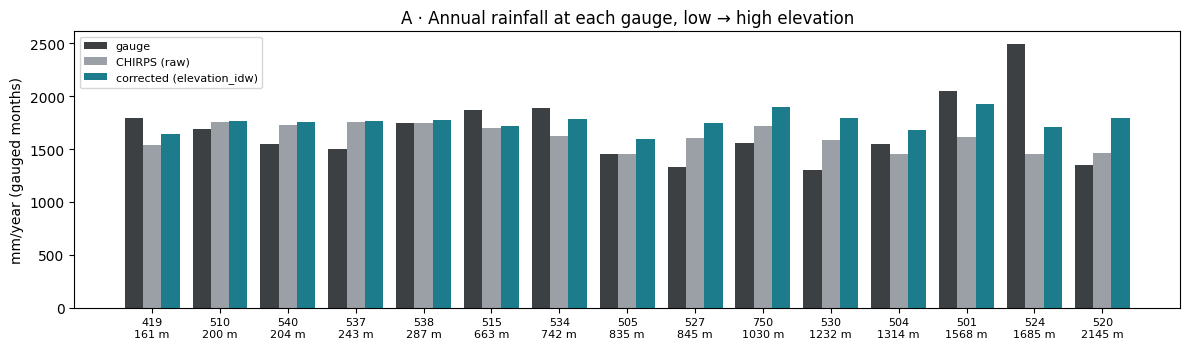

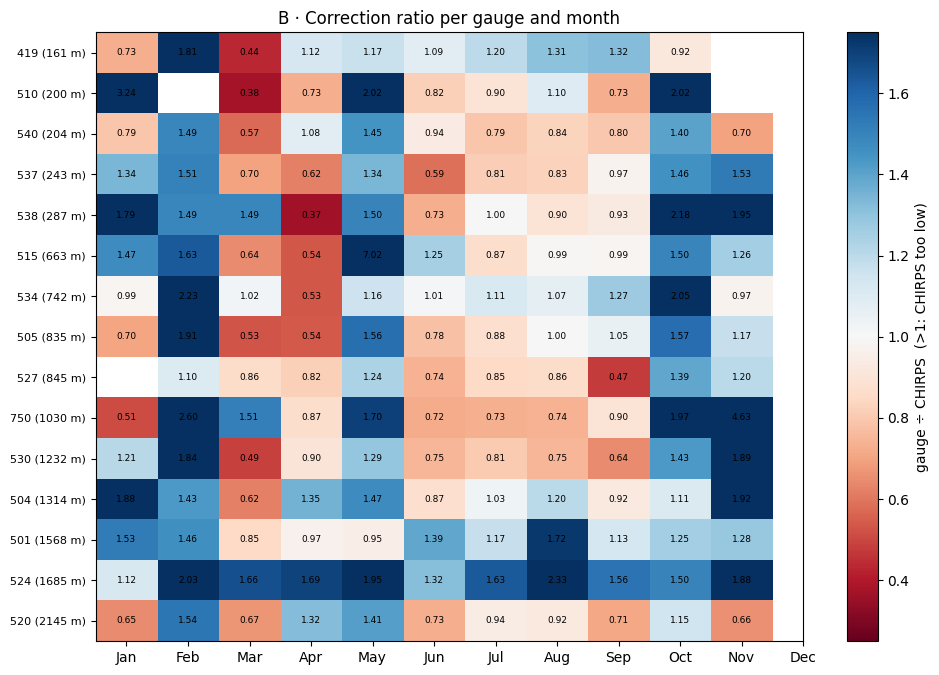

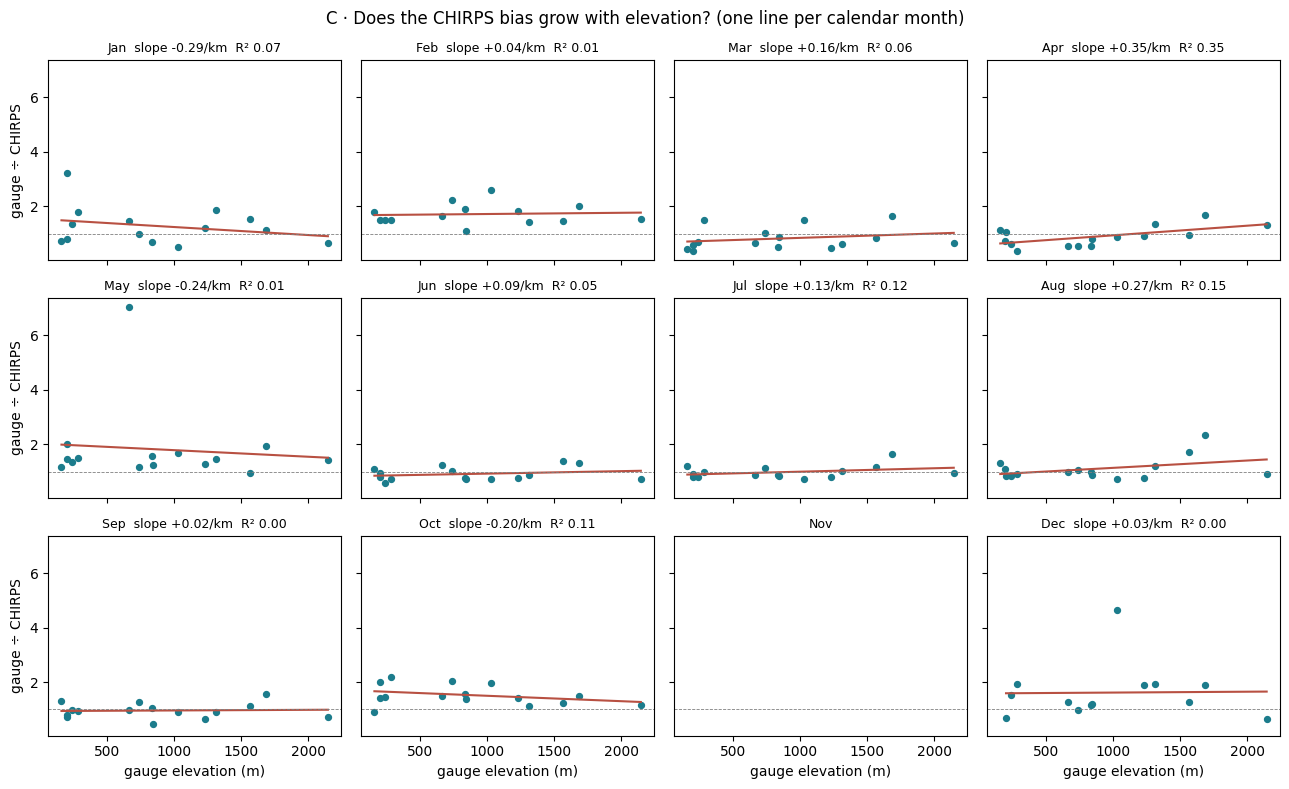

month  slope per 1000 m  intercept   R²  gauges
  Jan            -0.294       1.54 0.07      14
  Feb             0.045       1.68 0.01      14
  Mar             0.160       0.69 0.06      15
  Apr             0.354       0.59 0.35      15
  May            -0.242       2.03 0.01      15
  Jun             0.091       0.83 0.05      15
  Jul             0.126       0.87 0.12      15
  Aug             0.269       0.87 0.15      15
  Sep             0.023       0.94 0.00      15
  Oct            -0.199       1.70 0.11      15
  Dec             0.032       1.59 0.00      13


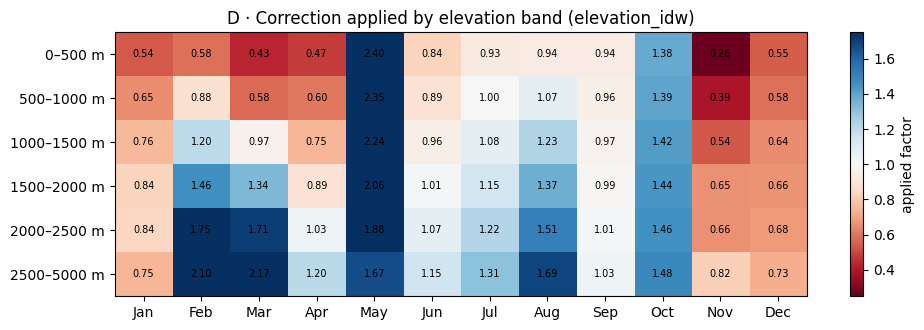

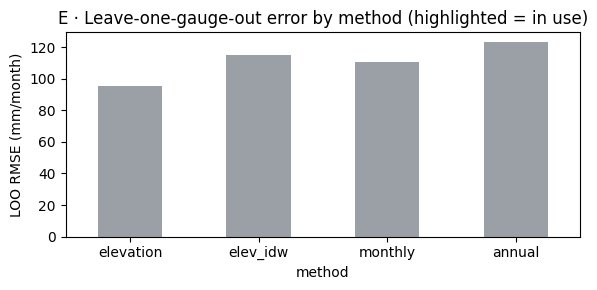

In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
tab = kw.precip_bias_table(P, stations, obs, utm=UTM)                 # gauge × month: obs, sat, ratio
gel = stations.set_index('id')['elev']
order = list(gel.loc[[g for g in gel.index if g in set(tab['gauge'])]].sort_values().index)

# A · annual totals per gauge — gauge vs raw CHIRPS vs corrected (sorted by elevation)
satr = kw._station_pixel_values(P, stations, UTM); satc = kw._station_pixel_values(Pc, stations, UTM)
ann = []
for g in order:
    o = obs[g].reindex(satr.index); ok = o.notna()
    yrs = max(ok.sum() / 12, 1e-9)
    ann.append({'gauge': g, 'elev': gel[g], 'gauge_mm': o[ok].sum() / yrs, 'CHIRPS_mm': satr[g][ok].sum() / yrs, 'corrected_mm': satc[g][ok].sum() / yrs})
ann = pd.DataFrame(ann)
fig, ax = plt.subplots(figsize=(12, 3.6)); x = np.arange(len(ann)); w = 0.27
ax.bar(x - w, ann['gauge_mm'], w, label='gauge', color='#3C4043'); ax.bar(x, ann['CHIRPS_mm'], w, label='CHIRPS (raw)', color='#9AA0A6')
ax.bar(x + w, ann['corrected_mm'], w, label=f'corrected ({_bc})', color='#1C7C8C')
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n{e:.0f} m" for g, e in zip(ann['gauge'], ann['elev'])], fontsize=8)
ax.set_ylabel('mm/year (gauged months)'); ax.legend(fontsize=8); ax.set_title('A · Annual rainfall at each gauge, low → high elevation'); plt.tight_layout(); plt.show()

# B · gauge ÷ CHIRPS ratio by gauge and calendar month (the evidence every method starts from)
R = tab.pivot(index='gauge', columns='month', values='ratio').reindex(order)
fig, ax = plt.subplots(figsize=(10, 0.35 * len(R) + 1.6))
im = ax.imshow(R.values, cmap='RdBu', vmin=0.25, vmax=1.75, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS); ax.set_yticks(range(len(R)))
ax.set_yticklabels([f"{g} ({gel[g]:.0f} m)" for g in R.index], fontsize=8)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.values[i, j]
        if np.isfinite(v): ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6.5)
plt.colorbar(im, ax=ax, label='gauge ÷ CHIRPS  (>1: CHIRPS too low)'); ax.set_title('B · Correction ratio per gauge and month')
plt.tight_layout(); plt.show()

# C · ratio vs elevation, month by month, with the fitted regression line (used by elevation / elev_idw)
fig, axs = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True); fits = []
for m, a in zip(range(1, 13), axs.ravel()):
    d = tab[tab['month'] == m]; a.scatter(d['elev'], d['ratio'], s=18, color='#1C7C8C')
    if len(d) >= 3 and np.ptp(d['elev']) > 0:
        b, c = np.polyfit(d['elev'], d['ratio'], 1); zz = np.linspace(d['elev'].min(), d['elev'].max(), 20)
        r2 = np.corrcoef(d['elev'], d['ratio'])[0, 1] ** 2
        a.plot(zz, c + b * zz, color='#B85042'); fits.append({'month': MONTHS[m - 1], 'slope per 1000 m': round(b * 1000, 3), 'intercept': round(c, 2), 'R²': round(r2, 2), 'gauges': len(d)})
        a.set_title(f'{MONTHS[m-1]}  slope {b*1000:+.2f}/km  R² {r2:.2f}', fontsize=9)
    else:
        a.set_title(MONTHS[m - 1], fontsize=9)
    a.axhline(1, color='grey', lw=0.6, ls='--')
for a in axs[-1]: a.set_xlabel('gauge elevation (m)')
for a in axs[:, 0]: a.set_ylabel('gauge ÷ CHIRPS')
fig.suptitle('C · Does the CHIRPS bias grow with elevation? (one line per calendar month)'); plt.tight_layout(); plt.show()
print(pd.DataFrame(fits).to_string(index=False))

# D · the correction factor actually applied, by elevation band and month (inside the basin)
_d = dem.squeeze(drop=True)
if tuple(_d.shape) != tuple(P.shape[-2:]):
    _d = _d.interp({_d.dims[-1]: P[P.dims[-1]].values, _d.dims[-2]: P[P.dims[-2]].values}, method='nearest')
Z = np.asarray(_d.values, float); M = np.asarray(mask.values) == 1
fac = (Pc / P.where(P > 1)).groupby('time.month').mean('time')            # mean factor per calendar month
bands = [0, 500, 1000, 1500, 2000, 2500, 5000]; lab = [f'{a}–{b} m' for a, b in zip(bands[:-1], bands[1:])]
tbl = np.full((len(lab), 12), np.nan)
for i, (lo, hi) in enumerate(zip(bands[:-1], bands[1:])):
    sel = M & (Z >= lo) & (Z < hi)
    if sel.sum() > 0:
        for j in range(12): tbl[i, j] = np.nanmean(np.asarray(fac.isel(month=j).values)[sel])
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(tbl, cmap='RdBu', vmin=0.25, vmax=1.75, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS); ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
for i in range(tbl.shape[0]):
    for j in range(12):
        if np.isfinite(tbl[i, j]): ax.text(j, i, f'{tbl[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='applied factor'); ax.set_title(f'D · Correction applied by elevation band ({_bc})'); plt.tight_layout(); plt.show()

# E · the methods side by side (leave-one-gauge-out)
ax = LOO['LOO RMSE (mm/month)'].astype(float).plot(kind='bar', figsize=(6, 3), color=['#1C7C8C' if m == _bc else '#9AA0A6' for m in LOO.index])
ax.set_ylabel('LOO RMSE (mm/month)'); ax.set_title('E · Leave-one-gauge-out error by method (highlighted = in use)'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### ✅ Checkpoint 1
Bias-corrected P moves toward the gauges; leave-one-out RMSE/bias is reported. If corrected P looks worse, check station coordinates (lon/lat) and that `DHM_OBS` dates align with `DATES`.

## 8 · Evaluate ET — the basin water-balance closure test

**What this does.** The honesty check on evapotranspiration. Over a multi-year mean, basin ET cannot
exceed precipitation (there's no other large water source here). This compares basin-mean corrected
**P** against basin-mean **ET** and reports the ratio ET/P.

**What to look for.** `ET/P` should be **below ~1** (typically ~0.5–0.8 for this basin). If ET > P,
either the ET product is too high or precipitation is under-corrected — fix it here, before Lab 3.

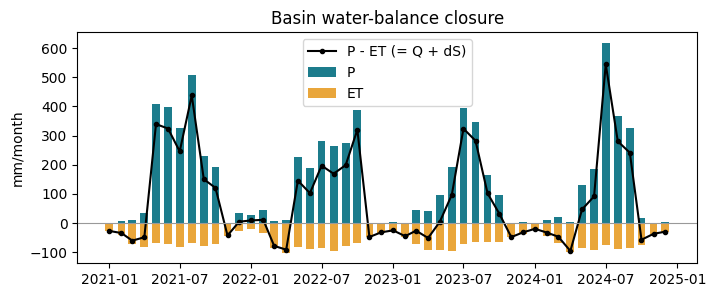

annual P=1735  ET=780  P-ET=955 mm


In [16]:
Pb = kw.basin_series(Pc, mask); Eb = kw.basin_series(ET, mask)
res = Pb - Eb
fig,ax=plt.subplots(figsize=(8,3))
ax.bar(Pb.index, Pb.values, width=20, label='P', color='#1C7C8C')
ax.bar(Eb.index, -Eb.values, width=20, label='ET', color='#E9A63B')
ax.plot(res.index, res.values, 'k-o', ms=3, label='P - ET (= Q + dS)')
ax.axhline(0, color='0.6', lw=0.8); ax.legend(); ax.set_ylabel('mm/month')
ax.set_title('Basin water-balance closure'); plt.show()
print('annual P=%.0f  ET=%.0f  P-ET=%.0f mm'%(Pb.groupby(Pb.index.year).sum().mean(),
      Eb.groupby(Eb.index.year).sum().mean(), res.groupby(res.index.year).sum().mean()))

### ✅ Checkpoint 2
Annual `P − ET` is positive and of a plausible magnitude for the basin. Cross-check ET against a second product (e.g. SSEBop or WaPOR) over stable land — large disagreement in monsoon months is expected; record it.

## 9 · Save outputs to Drive

**What this does.** Writes the analysis-ready cubes (`P`, `P_corrected`, `ET`, `LAI`, `NDM`, and
transpiration if used) back to the shared `west_rapti` folder so Lab 3 and Lab 4 can pick them up.

In [17]:
_outs = ['P.nc','P_corrected.nc','ET.nc','LAI.nc','NDM.nc'] + (['transp.nc'] if os.path.exists('transp.nc') else [])
saved = kw.save_outputs(_outs, OUT_DIR)
print('saved to', OUT_DIR, '->', saved)

saved to /content/drive/MyDrive/west_rapti/outputs -> ['P.nc', 'P_corrected.nc', 'ET.nc', 'LAI.nc', 'NDM.nc']


## What feeds Lab 3
`P_corrected.nc`, `ET.nc`, `LAI.nc`, `NDM.nc` become inputs to the analysis-ready data cube and the hydroloop model. **Record each product's native resolution and your §4b/§6 evaluation notes in the assumptions log** — every layer here is *resampled to the WA+ 300 m monthly grid*, which is finer than most native pixels, so the analysis resolution is not the information content. Use this table as the starting point (confirm the ones you actually selected via `ET_SOURCE` / `NDM_SOURCE`):

| Layer (variable) | Product used | Native resolution | Native cadence |
|---|---|---|---|
| Rainfall `P` | CHIRPS DAILY (`UCSB-CHG/CHIRPS/DAILY`) | ~0.05° (≈5.5 km) | daily → monthly sum |
| ET `ET` — mod16 | MOD16A2GF v061 (`MODIS/061/MOD16A2GF`) | 500 m | 8-day → monthly sum |
| ET `ET` — wapor | WaPOR v3 AETI (`FAO/WAPOR/3/L1_AETI_D`, GEE) | 326 m | dekadal → monthly sum |
| Leaf area `LAI` | MOD15A2H v061 (`MODIS/061/MOD15A2H`) | 500 m | 8-day → monthly mean |
| Biomass `NDM` — mod17 | MOD17A2HGF v061 GPP | 500 m | 8-day → monthly sum |
| Biomass `NDM` — wapor | WaPOR v3 L1-NPP-D | ~300 m | dekadal → monthly sum |
| Terrain (Lab 1) | Copernicus GLO-30 DEM | 30 m | static |
| Land cover (Lab 3) | classified stack, or ESA WorldCover | 10–30 m | annual |

So the coarsest control on the water balance is **rainfall (~5.5 km)**, not the 300 m grid — note that in the log, and flag any product whose §4b climatology looked non-physical or whose §6 closure was weak.

## 10 · Interactive — watch the inputs on a live map  🖱️

**What this does.** An optional live viewer: pick a variable, slide through the months, and click any
pixel to read its value. Purely for exploration/QC — it writes nothing.

In [18]:

# --- live layer viewer + month time-slider + click-to-inspect ---
import ee, geemap, pandas as pd
try: ee.Initialize(project=EE_PROJECT)
except Exception: pass
_dates = pd.date_range(START, END, freq='MS')[:-1]; _N = len(_dates)
_labels = [d.strftime('%Y-%m') for d in _dates]

def _monthly_ic(cid, band, how, scale, vmax=None):
    base = ee.ImageCollection(cid).select(band).filterBounds(region)
    if vmax is not None: base = base.map(lambda im: im.updateMask(im.lte(vmax)))
    def one(i):
        s = ee.Date(START).advance(i, 'month'); m = base.filterDate(s, s.advance(1, 'month'))
        red = m.sum() if how == 'sum' else m.mean()
        img = ee.Image(ee.Algorithms.If(m.size().gt(0), red, ee.Image.constant(0).selfMask())).multiply(scale)
        return img.set('system:time_start', s.millis())
    return ee.ImageCollection(ee.List.sequence(0, _N-1).map(one))

_ny = _N/12.0
P_ic  = _monthly_ic('UCSB-CHG/CHIRPS/DAILY','precipitation','sum',1.0)
ET_ic = _monthly_ic('MODIS/061/MOD16A2GF','ET','sum',0.1,vmax=32700)
LAI_ic= _monthly_ic('MODIS/061/MOD15A2H','Lai_500m','mean',0.1,vmax=100)
GPP_ic= _monthly_ic('MODIS/061/MOD17A2HGF','Gpp','sum',0.0001,vmax=30000)

Mv = geemap.Map(basemap='Esri.WorldImagery', center=[(BBOX[1]+BBOX[3])/2, (BBOX[0]+BBOX[2])/2], zoom=8)
Mv.addLayer(ET_ic.sum().divide(_ny).clip(region),  {'min':0,'max':1500,'palette':['#ffffcc','#a1dab4','#41b6c4','#225ea8']}, 'ET (mm/yr)', False)
Mv.addLayer(LAI_ic.mean().clip(region),            {'min':0,'max':5,'palette':['#ffffe5','#78c679','#006837']}, 'Leaf area (LAI)', False)
Mv.addLayer(GPP_ic.sum().divide(_ny).clip(region), {'min':0,'max':2,'palette':['#f7fcf5','#74c476','#00441b']}, 'Biomass (GPP)', False)
Mv.addLayer(region, {'color':'ffffff'}, 'Basin box', True)
Mv.add_time_slider(P_ic, {'min':0,'max':500,'palette':['#f7fbff','#9ecae1','#4292c6','#08519c','#062056']},
                   region=region, layer_name='Rainfall (mm/month)', labels=_labels, time_interval=1)
_Py = P_ic.sum().divide(_ny); _ETy = ET_ic.sum().divide(_ny); _LAIy = LAI_ic.mean(); _GPPy = GPP_ic.sum().divide(_ny)
def _inspect(**k):
    if k.get('type') != 'click': return
    lat, lon = k['coordinates']; pt = ee.Geometry.Point([lon, lat]); o = {}
    for nm, img, sc in [('P mm/yr',_Py,5000),('ET mm/yr',_ETy,500),('LAI',_LAIy,500),('GPP',_GPPy,500)]:
        try:
            v = img.reduceRegion(ee.Reducer.first(), pt, sc).getInfo()
            o[nm] = round(list(v.values())[0], 2) if v and list(v.values())[0] is not None else None
        except Exception as e: o[nm] = f'err'
    print(f'@ lon={lon:.3f}, lat={lat:.3f}  ->  {o}')
Mv.on_interaction(_inspect)
print('Slide the months; toggle layers (top-right); click a pixel to inspect.')
Mv


Slide the months; toggle layers (top-right); click a pixel to inspect.


Map(center=[28.14740578977713, 82.407488264426], controls=(WidgetControl(options=['position', 'transparent_bg'…